# GPX6 genome-wide — where the promoter deletion sits in the GEA

**The variant:** Chr4:7,011,705, a **1,164 bp deletion 330 bp upstream of GPX6** (AT4G11600,
phospholipid hydroperoxide glutathione peroxidase, mitochondrial), 27 founder carriers, MAF 0.118.
It is Bonferroni-significant on **6 axes / 5 climate clusters**: pc1, bio11, bio6, bio1, bio3, bio12
(all but bio12 are cold-temperature axes). Full chain: `genes/convergence/results/audit/GPX6_audit.txt`.

**Layout** (same as `peak_alignment_manhattan_gea.ipynb`): SVs point up, SNPs point down, on one
genome axis; dashed lines are each class's own Bonferroni (0.05 / n records of that class); SNPs
with p > 0.01 are not drawn. Open red circles = SV peaks with no significant SNP within 10 kb.
**The GPX6 deletion is the filled red diamond**, with a vertical guide through both halves.

This notebook shows **pc1** only; the other five axes build on demand
(`python _build_gpx6_manhattan_nb.py bio11 bio6 bio1 bio3 bio12`).

Per axis: the genome-wide figure, then a ±250 kb zoom on the locus, where the SNP rivals that
track the same haplotype are visible (26 of them beat 85% of the deletion's garden-level |r|, and
none changes a TF binding site — that asymmetry, not the p-value, is the argument for the deletion).

Raw LFMM p, gen9, MAF > 0.05, no inflation correction (λ 1.37–2.54 on these records).

In [1]:
import os, sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
def _tree_root(start=None):
    d = os.path.abspath(start or os.getcwd())
    while d != os.path.dirname(d):
        if os.path.basename(d) == "grenenet_selection" and os.path.exists(os.path.join(d, "lib.py")):
            return d
        d = os.path.dirname(d)
    raise RuntimeError("no grenenet_selection root above " + os.getcwd())
GS = _tree_root()
sys.path.insert(0, GS); sys.path.insert(0, f"{GS}/blocks"); sys.path.insert(0, f"{GS}/genes/convergence")
import lib, blocks_tiling as bt, plot_theme as TH
TH.apply()
WZAIN = f"{GS}/r2_gea_nonsnp/phase1_replication/results/multiaxis/wza_in_clq09_tile"
PLOTS = f"{GS}/notebooks/plots"; os.makedirs(PLOTS, exist_ok=True)
WINDOW, ZOOM_KB, SNP_FLOOR = 10000, 250, 2.0

# the candidate
GENE, SYM = "AT4G11600", "GPX6"
VCHROM, VPOS, VSIZE = "Chr4", 7011705, 1164
GSTART, GEND = 7009769, 7011375

CHROM_LEN = {"Chr1": 30427671, "Chr2": 19698289, "Chr3": 23459830, "Chr4": 18585056, "Chr5": 26975502}
GAP = 3_500_000
CH = list(CHROM_LEN); OFF = {}; _a = 0
for _c in CH: OFF[_c] = _a; _a += CHROM_LEN[_c] + GAP
GENOME = _a - GAP
VX = OFF[VCHROM] + VPOS

SVCOL, SVLIGHT = "#3F7D4A", "#8DB896"
SNPCOL = ("#8A8A8A", "#C4C4C4")
AXISNAME = {"pc1": "climate PC1", "bio1": "annual mean temperature",
            "bio3": "isothermality", "bio6": "min temperature of coldest month",
            "bio11": "mean temperature of coldest quarter", "bio12": "annual precipitation"}

def load(cls, axis):
    d = pd.read_csv(f"{WZAIN}/lfmm_{cls}_gen9_{axis}.csv", usecols=["chrom", "pos", "MAF", "pval"])
    d = d[d.MAF > 0.05].copy()
    d["block"] = bt.assign_tiling(d.chrom.to_numpy(), d.pos.to_numpy(), r2=0.9)
    d["nlp"] = -np.log10(d.pval.clip(lower=1e-300))
    d["x"] = d.chrom.map(OFF) + d.pos
    d.attrs["bar"] = -np.log10(0.05 / len(d))
    return d

def sv_snp_peaks(D, window):
    # significant blocks per class -> record-span extents -> merged within `window` -> SV peaks,
    # flagged sv_only when the peak carries no significant SNP (the rule of the main notebook)
    rows = []
    for cls in ["sv", "snp"]:
        d = D[cls]; lead = d.groupby("block").nlp.max(); sb = set(lead.index[lead > d.attrs["bar"]])
        e = d[d.block.isin(sb)].groupby("block").agg(chrom=("chrom", "first"), start=("pos", "min"),
                                                     end=("pos", "max")).reset_index()
        e["cls"] = cls; rows.append(e)
    t = pd.concat(rows).sort_values(["chrom", "start"])
    lid, cur, pch, pend = [], -1, None, -np.inf
    for r in t.itertuples():
        if r.chrom != pch or r.start - pend > window: cur += 1; pend = r.end
        else: pend = max(pend, r.end)
        pch = r.chrom; lid.append(cur)
    t["locus"] = lid
    out = []
    for lid, g in t.groupby("locus"):
        ch, lo, hi = g.chrom.iloc[0], g.start.min(), g.end.max()
        if "sv" not in set(g.cls): continue
        q = D["sv"][(D["sv"].chrom == ch) & D["sv"].pos.between(lo, hi)]
        b = q.loc[q.nlp.idxmax()]
        out.append(dict(chrom=ch, start=lo, end=hi, pos=int(b.pos), x=int(b.x), nlp=float(b.nlp),
                        sv_only="snp" not in set(g.cls)))
    return pd.DataFrame(out)

def gpx6_record(D):
    # the deletion's own -log10 p per class on this axis (NaN if the record is absent)
    out = {}
    for cls in ["sv", "nonsnp", "snp"]:
        q = D[cls][(D[cls].chrom == VCHROM) & (D[cls].pos == VPOS)]
        out[cls] = float(q.nlp.max()) if len(q) else np.nan
    return out

print("loaded helpers ·", SYM, f"{VCHROM}:{VPOS:,} ({VSIZE} bp deletion)")

loaded helpers · GPX6 Chr4:7,011,705 (1164 bp deletion)


In [2]:
def manh(ax, d, cols, sign=1, s=1.6, alt=True):
    for i, ch in enumerate(CH):
        k = d[d.chrom == ch]
        if len(k):
            ax.scatter(k.x, sign * k.nlp, s=s, c=cols[i % 2] if alt else cols[0],
                       linewidths=0, rasterized=True, zorder=1)

def gpx6_mark(ax, nlp_sv, shift, lo, hi, label=True):
    # vertical guide through both halves + a filled diamond on the deletion's SV point
    if not (lo <= VX <= hi): return
    ax.axvline(VX, color=TH.ACCENT, lw=1.0, ls=(0, (4, 3)), alpha=0.55, zorder=2)
    if np.isfinite(nlp_sv):
        ax.scatter([VX], [nlp_sv], marker="D", s=70, color=TH.ACCENT, edgecolor="white",
                   linewidth=0.8, zorder=7, clip_on=False)
    if label:
        ax.annotate(f"{SYM}\n{VCHROM}:{VPOS:,}", (VX, ax.get_ylim()[1]), xytext=(6, -4),
                    textcoords="offset points", ha="left", va="top", fontsize=8.5, color=TH.ACCENT)

def miami(axis, D, P, lo=0, hi=None, zoom=False, fname=None):
    hi = GENOME if hi is None else hi
    fig, ax = plt.subplots(figsize=(17, 6.2 if not zoom else 5.4))
    sv = D["sv"]; snp = D["snp"]
    inx = lambda d: d[(d.x >= lo) & (d.x <= hi)]
    SHIFT = SNP_FLOOR - 0.5 if not zoom else 0.0        # the p>0.01 cut only applies genome-wide
    s = inx(snp) if zoom else inx(snp[snp.nlp >= SNP_FLOOR]).assign(nlp=lambda d: d.nlp - SHIFT)
    manh(ax, inx(sv), (SVCOL, SVLIGHT), +1, s=3 if zoom else 1.6, alt=not zoom)
    manh(ax, s, SNPCOL, -1, s=3 if zoom else 1.6, alt=not zoom)
    ax.axhline(sv.attrs["bar"], ls="--", lw=0.8, color=TH.MUTED)
    ax.axhline(-(snp.attrs["bar"] - SHIFT), ls="--", lw=0.8, color=TH.MUTED)
    ax.axhline(0, color=TH.AXIS, lw=0.8)
    if not zoom:
        q = P[P.sv_only]
        ax.scatter(q.x, q.nlp, s=110, facecolor="none", edgecolor="#B03A4B", linewidth=1.3,
                   alpha=0.55, zorder=5, clip_on=False)
    top = max(inx(sv).nlp.max(), 1) * 1.18
    bot = max(inx(snp).nlp.max() - SHIFT, 1) * 1.10
    ax.set_ylim(-bot, top)
    up = np.arange(0, top, 2 if zoom else 4)
    dn = np.arange(2 if zoom else 4, inx(snp).nlp.max() + 1, 2 if zoom else 4)
    ax.set_yticks(np.r_[-(dn[::-1] - SHIFT), up])
    ax.set_yticklabels([f"{v:g}" for v in dn[::-1]] + [f"{v:g}" for v in up])
    ax.set_ylabel("−log10 p\nSNP ↓        SV ↑")
    TH.grid_only(ax, "y")
    gpx6_mark(ax, gpx6_record(D)["sv"], SHIFT, lo, hi)
    if zoom:
        ax.axvspan(OFF[VCHROM] + GSTART, OFF[VCHROM] + GEND, color=TH.ACCENT, alpha=0.10, lw=0, zorder=0)
        # ticks on round 50 kb positions, not on the window edges (which round to the wrong label)
        step = 50_000
        t0 = int(np.ceil((lo - OFF[VCHROM]) / step) * step)
        tk = np.arange(t0, hi - OFF[VCHROM], step)
        ax.set_xticks(OFF[VCHROM] + tk); ax.set_xticklabels([f"{t/1e6:.2f}" for t in tk], fontsize=8.5)
        ax.set_xlabel(f"{VCHROM} position (Mb)")
        ax.set_xlim(lo, hi)
    else:
        pad = 0.015 * GENOME
        ax.set_xlim(-pad, GENOME + pad)
        ax.set_xticks([OFF[c] + CHROM_LEN[c] / 2 for c in CH]); ax.set_xticklabels(CH, fontsize=11)
        ax.tick_params(axis="x", length=0)
    h = [Line2D([], [], marker="D", ls="", color=TH.ACCENT, markersize=8,
                label=f"{SYM} promoter deletion ({VSIZE} bp)")]
    if not zoom:
        h.append(Line2D([], [], marker="o", ls="", markerfacecolor="none", markeredgecolor="#B03A4B",
                        markeredgewidth=1.3, markersize=10, alpha=0.7, label="new SV peak"))
    h.append(Line2D([], [], ls="--", color=TH.MUTED, label="Bonferroni"))
    fig.legend(handles=h, loc="lower center", bbox_to_anchor=(0.5, 0.9), ncol=len(h), fontsize=9.5)
    if fname:
        for ext in ["png", "pdf"]:
            plt.savefig(f"{PLOTS}/{fname}.{ext}", dpi=200, bbox_inches="tight", pad_inches=0.25)
    plt.show()

def run(axis):
    D = {c: load(c, axis) for c in ["snp", "sv"]}
    D["nonsnp"] = load("nonsnp", axis)
    P = sv_snp_peaks(D, WINDOW)
    g = gpx6_record(D)
    rank_sv = int((D["sv"].nlp > g["sv"]).sum() + 1) if np.isfinite(g["sv"]) else -1
    print(f"{axis} ({AXISNAME.get(axis, '')}): GPX6 deletion −log10 p = "
          f"{g['sv']:.2f} (SV), {g['nonsnp']:.2f} (non-SNP pool); SV bar {D['sv'].attrs['bar']:.2f}, "
          f"SNP bar {D['snp'].attrs['bar']:.2f}; rank {rank_sv} of {len(D['sv']):,} SVs genome-wide; "
          f"{len(P)} SV peaks, {P.sv_only.sum()} with no significant SNP within {WINDOW // 1000} kb")
    miami(axis, D, P, fname=f"gpx6_miami_{axis}")
    lo, hi = VX - ZOOM_KB * 1000, VX + ZOOM_KB * 1000
    miami(axis, D, P, lo, hi, zoom=True, fname=f"gpx6_zoom_{axis}")
    return D, P

## pc1

pc1 (climate PC1): GPX6 deletion −log10 p = 9.68 (SV), 10.15 (non-SNP pool); SV bar 5.74, SNP bar 7.61; rank 2 of 27,586 SVs genome-wide; 40 SV peaks, 25 with no significant SNP within 10 kb


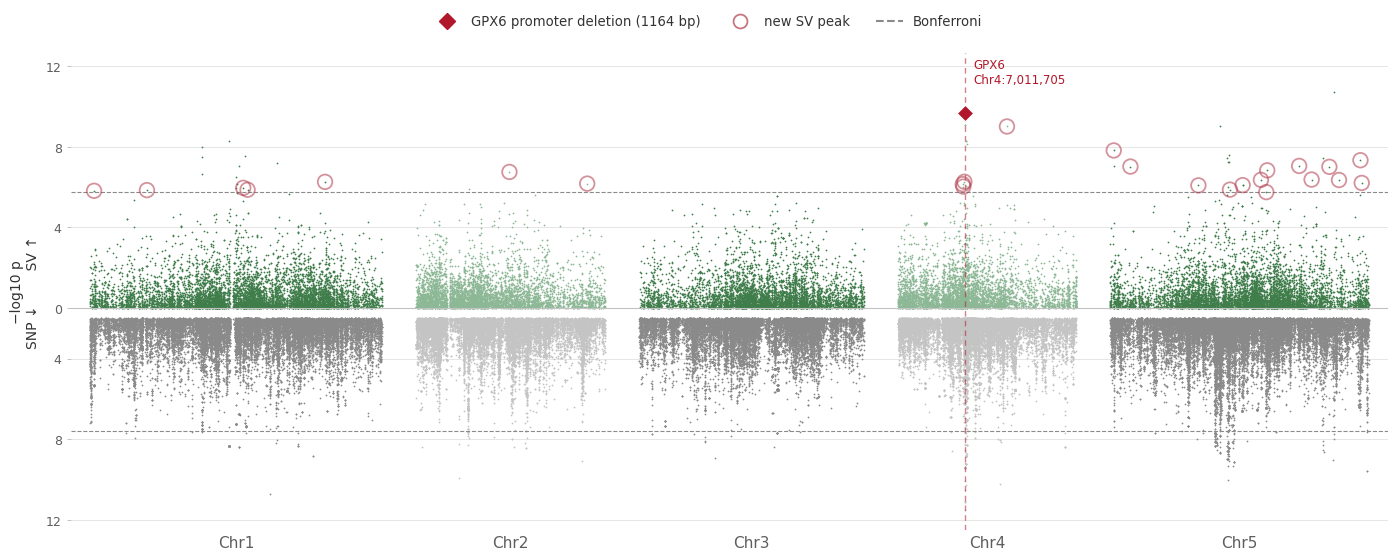

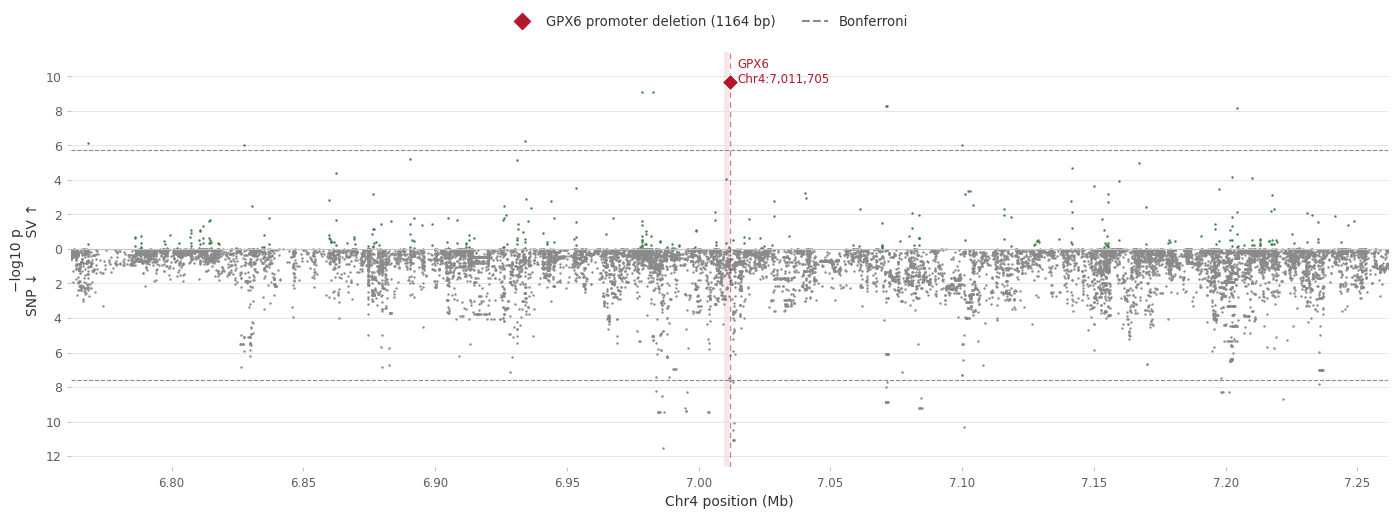

In [3]:
D, P = run("pc1")

### pc1 — zoom on the locus, with linkage to the deletion

A ±120 kb LocusZoom view of the same pc1 scan, asking whether the SNP signal here is the deletion seen
through linkage, and whether a SNP-only analysis would have reached GPX6.

**Which record the deletion is.** The panel decomposes Chr4:7,011,705 into **11 near-identical
deletion alleles** (REF 1,225 bp → ALT 50–63 bp), all called in the same **78 of 231 founders**
(call rate 33.8%, the 1.3th percentile among SVs within 1 Mb). The audit's "27 carriers" is the union
of all 11. The record the GEA actually tested is store row 1517046 = the single **13-carrier** allele
(REF 1225 → ALT 61, −1,164 bp); the other ten carry 1–4 founders each and share **no** carriers with
it. Everything here indexes on that 13-carrier allele, not the union.

**Linkage.** Colours are **founder r²** — classical LD between carrier vectors, over founders called
at both records. For this variant that is at most 78 of 231, so it is real LD measured on a third of
the panel. SNPs need ≥ 40 shared called founders and MAF ≥ 0.02 to be drawn. Every SV record is
matched to its panel record exactly on (pos, ref_len, alt_len), so no allele-union ambiguity enters.
As a cross-check the printed table also carries **pool-frequency r²** (correlation of gen-9
frequencies across the 352 pools, the scale the GEA itself runs on); for the SNPs that matters the
two agree closely (lead SNP 0.751 vs 0.745).

**(a)** −log10 p on pc1 for every Chr4 record in the window: SNPs as circles, **all 40 SVs (> 50 bp,
indels excluded) as diamonds**, both coloured by founder r² to the deletion. The GPX6 deletion is the
large red diamond. Dashed lines are each class's own Bonferroni (SNP 0.05/2,016,071; SV 0.05/27,586).
**(b)** every gene in the window as a simple block, labelled by **UniProt/TAIR symbol** where one
exists and by AGI id otherwise (annotation from `annotate_genes_tair_uniprot.py`, cached in
`genes/convergence/results/gpx6_window_gene_annotation.csv`; the AGI id for every gene is printed
under the figure), with the deletion's 1,164 bp span below. GPX6 in red.

11 deletion alleles; GEA record = 13-carrier allele, called in 78; union 27


SV records in the window: 147; founder r2 computable for 147


57 genes in the window
SVs clearing the SV Bonferroni (5.74) in the window: 7


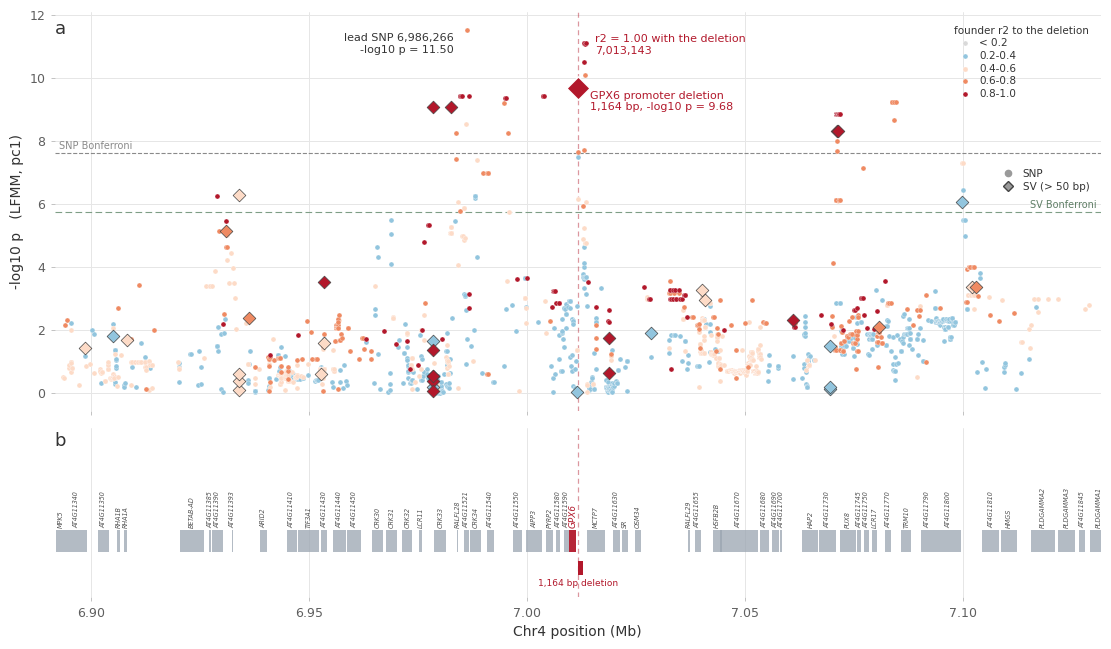


genes in the window (label -> AGI -> UniProt protein name):
  MPK5         AT4G11330  Mitogen-activated protein kinase 5 (AtMPK5) (MAP kinase 5) (EC 2.7.11.24)
  AT4G11340    AT4G11340  Disease resistance protein (TIR-NBS-LRR class) family
  AT4G11350    AT4G11350  Transferring glycosyl group transferase (DUF604)
  RHA1B        AT4G11360  E3 ubiquitin-protein ligase RHA1B (EC 2.3.2.27) (RING-H2 finger A1b) (RING-H2 zinc
  RHA1A        AT4G11370  Probable E3 ubiquitin-protein ligase RHA1A (EC 2.3.2.27) (RING-H2 finger A1a) (RIN
  BETAB-AD     AT4G11380  Beta-adaptin-like protein B (At-bB-Ad) (At-betaB-Ad) (AP complex subunit beta-B) (
  AT4G11385    AT4G11385  Uncharacterized protein
  AT4G11390    AT4G11390  Cysteine/Histidine-rich C1 domain family protein
  AT4G11393    AT4G11393  Putative defensin-like protein 202
  ARID2        AT4G11400  AT-rich interactive domain-containing protein 2 (ARID domain-containing protein 2)
  AT4G11410    AT4G11410  NAD(P)-binding Rossmann-fold superfa

In [4]:

import scipy.sparse as sp
from matplotlib.patches import Rectangle
HALF, AXIS_LD, STORE_ROW = 120_000, "pc1", 1517046
LDBIN = [(0.8, "#B2182B", "0.8-1.0"), (0.6, "#EF8A62", "0.6-0.8"), (0.4, "#FDDBC7", "0.4-0.6"),
         (0.2, "#92C5DE", "0.2-0.4"), (-1, "#D9D9D9", "< 0.2")]
PMDIR = f"{lib.GEA}/common/results/pool_matrices"

_sa = pd.read_csv(f"{WZAIN}/lfmm_snp_gen9_{AXIS_LD}.csv", usecols=["chrom", "pos", "MAF", "pval"])
_sa = _sa[_sa.MAF > 0.05]
BAR_SNP = np.log10(len(_sa) / 0.05)
_s4 = _sa[_sa.chrom == "Chr4"].copy(); _s4["nlp"] = -np.log10(_s4.pval.clip(lower=1e-300))
_sv = pd.read_csv(f"{WZAIN}/lfmm_sv_gen9_{AXIS_LD}.csv",
                  usecols=["chrom", "pos", "ref_len", "alt_len", "MAF", "pval"])
_sv = _sv[_sv.MAF > 0.05].copy(); _sv["nlp"] = -np.log10(_sv.pval.clip(lower=1e-300))
BAR_SV = np.log10(len(_sv) / 0.05)
DEL_NLP = float(_sv[(_sv.chrom == VCHROM) & (_sv.pos == VPOS)].nlp.iloc[0])
LEAD = int(_s4.loc[_s4.nlp.idxmax(), "pos"]); LEAD_NLP = float(_s4.nlp.max())

_B = f"{lib.PROJ}/panel/arch3/chr4/var_pa_231_arch3_chr4"
_mt = np.load(f"{_B}.meta.npz", allow_pickle=True)
_pp = _mt["pos"].astype(np.int64); _rl = _mt["ref_len"].astype(np.int64); _al = _mt["alt_len"].astype(np.int64)
_PA = sp.load_npz(f"{_B}.var_pa.npz").tocsc(); _CA = sp.load_npz(f"{_B}.var_called.npz").tocsc()
_di = np.where((_pp == VPOS) & ((_rl - _al) > 1000))[0]
IDX = int(_di[np.argmax(np.asarray((_PA[:, _di] > 0).sum(0)).ravel())])
gd = np.asarray((_PA[:, IDX] > 0).todense()).ravel(); cd = np.asarray((_CA[:, IDX] > 0).todense()).ravel()
_evg = np.asarray((_PA[:, _di] > 0).sum(1)).ravel() > 0
print(f"{_di.size} deletion alleles; GEA record = {gd.sum()}-carrier allele, called in {cd.sum()}; union {_evg.sum()}")
_issnp = (_rl == 1) & (_al == 1)
_wj = np.where(_issnp & (_pp > VPOS - HALF) & (_pp < VPOS + HALF))[0]
_PAs = (_PA[:, _wj] > 0).toarray(); _CAs = (_CA[:, _wj] > 0).toarray()
_rows = []
for _k in range(len(_wj)):
    _m = cd & _CAs[:, _k]
    if _m.sum() < 40: continue
    _y = _PAs[_m, _k].astype(float); _x = gd[_m].astype(float); _f = _y.mean()
    if _x.std() == 0 or _y.std() == 0 or min(_f, 1 - _f) < 0.02: continue
    _rows.append((int(_pp[_wj[_k]]), float(np.corrcoef(_x, _y)[0, 1] ** 2)))
FD = pd.DataFrame(_rows, columns=["pos", "r2"]).groupby("pos", as_index=False).r2.max()
SVW = _sv[(_sv.chrom == "Chr4") & (_sv.pos > VPOS - HALF) & (_sv.pos < VPOS + HALF)].copy()
_key = {}
for _i in np.where((_pp > VPOS - HALF) & (_pp < VPOS + HALF) & (np.abs(_al - _rl) > 50))[0]:
    _k3 = (int(_pp[_i]), int(_rl[_i]), int(_al[_i]))
    _n = int((_PA[:, _i] > 0).sum())
    if _k3 not in _key or _n > _key[_k3][1]:
        _key[_k3] = (int(_i), _n)
_r2sv, _nsv = [], []
for _, _r in SVW.iterrows():
    _hit = _key.get((int(_r.pos), int(_r.ref_len), int(_r.alt_len)))
    if _hit is None:
        _r2sv.append(np.nan); _nsv.append(0); continue
    _j = _hit[0]
    _gy = np.asarray((_PA[:, _j] > 0).todense()).ravel(); _cy = np.asarray((_CA[:, _j] > 0).todense()).ravel()
    _m = cd & _cy
    _x = gd[_m].astype(float); _y = _gy[_m].astype(float)
    _r2sv.append(float(np.corrcoef(_x, _y)[0, 1] ** 2) if (_m.sum() >= 40 and _x.std() > 0 and _y.std() > 0) else np.nan)
    _nsv.append(int(_gy.sum()))
SVW["r2"] = _r2sv; SVW["carriers"] = _nsv; SVW["dlen"] = SVW.alt_len - SVW.ref_len
SVW["is_target"] = (SVW.pos == VPOS) & (SVW.ref_len == int(_rl[IDX])) & (SVW.alt_len == int(_al[IDX]))
print(f"SV records in the window: {len(SVW)}; founder r2 computable for {SVW.r2.notna().sum()}")
_IN = np.load(f"{lib.AF_STORE}/index_snp.npz", allow_pickle=True)
_As = np.load(f"{PMDIR}/pool_gen9_snp_af.npy", mmap_mode="r")
_dv = np.asarray(np.load(f"{PMDIR}/pool_gen9_nonsnp_af.npy", mmap_mode="r")[:, STORE_ROW], dtype=float)
_sel = np.where((_IN["chrom"] == "Chr4") & (_IN["pos"] > VPOS - HALF) & (_IN["pos"] < VPOS + HALF))[0]
_V = np.asarray(_As[:, _sel], dtype=float); _ok = np.isfinite(_dv)
_Vc = _V[_ok] - _V[_ok].mean(0); _dc = _dv[_ok] - _dv[_ok].mean()
_den = np.sqrt((_Vc ** 2).sum(0) * (_dc ** 2).sum())
_rp = np.divide((_Vc * _dc[:, None]).sum(0), _den, out=np.zeros(len(_sel)), where=_den > 0)
PD = pd.DataFrame(dict(pos=_IN["pos"][_sel], r2_pool=_rp ** 2)).groupby("pos", as_index=False).r2_pool.max()
M = (_s4[(_s4.pos > VPOS - HALF) & (_s4.pos < VPOS + HALF)]
     .merge(FD, on="pos", how="left").merge(PD, on="pos", how="left"))
M["r2"] = M.r2.fillna(-1)

LO, HI = VPOS - HALF, VPOS + HALF
# gene symbols: TAIR GO + UniProt, via r2_gea_nonsnp/phase1_replication/annotate_genes_tair_uniprot.py
#   $PY annotate_genes_tair_uniprot.py --genes-from <window genes> --out results/gpx6_window_gene_annotation.csv
_ann = pd.read_csv(f"{GS}/genes/convergence/results/gpx6_window_gene_annotation.csv")
SYMOF = dict(zip(_ann.gene, _ann.symbol.fillna("")))
PROTOF = dict(zip(_ann.gene, _ann.protein_name.fillna("")))
_label = lambda g: (SYMOF.get(g) or g) if (SYMOF.get(g) or g) != g else g
_G = lib.load_genes()
_g = _G[(_G.chrom == "Chr4") & (_G.end >= LO) & (_G.start <= HI)].sort_values("start")
print(f"{len(_g)} genes in the window")
# the SVs in this window that clear the SV Bonferroni on this axis, with the gene each sits in or
# nearest to (promoter = within 2 kb upstream of the TSS, strand-aware)
_gg = _g.copy(); _gg["tss"] = np.where(_gg.strand == "+", _gg.start, _gg.end)
def _target(p, e):
    _b = _gg[(_gg.start <= e) & (_gg.end >= p)]
    if len(_b):
        return _b.iloc[0].gene, "in gene"
    _u = np.where(_gg.strand == "+", _gg.tss - e, p - _gg.tss)
    _pr = _gg[(_u > 0) & (_u <= 2000)]
    if len(_pr):
        return _pr.iloc[int(np.argmin(_u[(_u > 0) & (_u <= 2000)]))].gene, "promoter"
    _d = np.minimum((_gg.start - e).abs(), (_gg.end - p).abs())
    return _gg.iloc[int(np.argmin(_d))].gene, "nearest"
SVSIG = SVW[SVW.nlp >= BAR_SV].copy()
SVSIG["end"] = SVSIG.pos + np.maximum(SVSIG.ref_len - 1, 0)
SVSIG[["target_gene", "placement"]] = [_target(r.pos, r.end) for r in SVSIG.itertuples()]
SVSIG["sym"] = [SYM if t == GENE else (SYMOF.get(t) or t) for t in SVSIG.target_gene]
SVSIG["size_lab"] = [f"{d:+,} bp".replace("+", "+").replace("-", "\u2212") for d in SVSIG.dlen]
print(f"SVs clearing the SV Bonferroni ({BAR_SV:.2f}) in the window: {len(SVSIG)}")

def draw_zoom(fname, mark_candidates=False):
    fig = plt.figure(figsize=(13.5, 7.6))
    _gs = fig.add_gridspec(2, 1, height_ratios=[2.35, 1.0], hspace=0.06)
    XL = (LO / 1e6, HI / 1e6); _mb = lambda p: np.asarray(p) / 1e6

    a = fig.add_subplot(_gs[0]); TH.grid_only(a); TH.panel(a, "a")
    for _lo, _col, _lab in LDBIN[::-1]:
        _k = M[(M.r2 > _lo) & (M.r2 <= (1.01 if _lo == 0.8 else _lo + 0.2))]
        a.scatter(_mb(_k.pos), _k.nlp, s=13, c=_col, linewidths=0.2, edgecolor="white",
                  zorder=3 if _lo >= 0.4 else 2, label=_lab)
    a.axhline(BAR_SNP, ls="--", lw=0.8, color=TH.MUTED)
    a.annotate("SNP Bonferroni", (XL[0], BAR_SNP), xytext=(3, 3), textcoords="offset points", fontsize=7, color=TH.MUTED)
    _sother = SVW[~SVW.is_target]
    for _lo, _col, _lab in LDBIN[::-1]:
        _k = _sother[(_sother.r2.fillna(-1) > _lo) & (_sother.r2.fillna(-1) <= (1.01 if _lo == 0.8 else _lo + 0.2))]
        a.scatter(_mb(_k.pos), _k.nlp, s=42, c=_col, marker="D", linewidths=0.5, edgecolor="#444444", zorder=5)
    a.axhline(BAR_SV, ls=(0, (6, 3)), lw=0.8, color="#7F9E86")
    a.annotate("SV Bonferroni", (XL[1], BAR_SV), xytext=(-3, 3), textcoords="offset points",
               fontsize=7, color="#5F7E66", ha="right")
    a.scatter([VPOS / 1e6], [DEL_NLP], marker="D", s=140, color=TH.ACCENT, edgecolor="white", linewidth=1.1, zorder=7)
    a.annotate(f"{SYM} promoter deletion\n{VSIZE:,} bp, -log10 p = {DEL_NLP:.2f}", (VPOS / 1e6, DEL_NLP),
               xytext=(9, -2), textcoords="offset points", fontsize=8, color=TH.ACCENT, va="top")
    a.annotate(f"lead SNP {LEAD:,}\n-log10 p = {LEAD_NLP:.2f}", (LEAD / 1e6, LEAD_NLP), xytext=(-9, -2),
               textcoords="offset points", fontsize=8, color=TH.LABEL, ha="right", va="top")
    _tw = M[M.r2 >= 0.999]
    if len(_tw):
        _t0 = _tw.iloc[0]
        a.annotate(f"r2 = 1.00 with the deletion\n{int(_t0.pos):,}", (_t0.pos / 1e6, _t0.nlp), xytext=(8, 6),
                   textcoords="offset points", fontsize=8, color="#B2182B")
    a.axvline(VPOS / 1e6, color=TH.ACCENT, lw=0.9, ls=(0, (4, 3)), alpha=0.45, zorder=1)
    a.set_ylabel("-log10 p   (LFMM, pc1)"); a.set_xlim(*XL); a.set_xticklabels([])
    _lg = a.legend(title="founder r2 to the deletion", frameon=False, fontsize=7.5, title_fontsize=7.5,
                   loc="upper right", bbox_to_anchor=(0.998, 0.99), handletextpad=0.4, labelspacing=0.25)
    _lg._legend_box.align = "left"
    from matplotlib.lines import Line2D as _L2D
    _h2 = [_L2D([], [], marker="o", ls="", ms=4.5, color="#9A9A9A", label="SNP"),
           _L2D([], [], marker="D", ls="", ms=5.0, color="#9A9A9A", mec="#444444", label="SV (> 50 bp)")]
    _lg2 = a.legend(handles=_h2, frameon=False, fontsize=7.5, loc="upper right",
                    bbox_to_anchor=(0.998, 0.63), handletextpad=0.4, labelspacing=0.25)
    a.add_artist(_lg)

    # ---- panel b: JBrowse-style gene models, every gene labelled
    b = fig.add_subplot(_gs[1]); TH.grid_only(b, axis="x"); TH.panel(b, "b")
    Y0, DY = 0.30, 0.16
    BYLO, BYHI = (Y0 - DY * (7.7 if mark_candidates else 2.6), Y0 + DY * 5.2)
    # vertical guides stop at the bottom of the variant mark so they do not strike through the labels
    _gfrac = (Y0 - DY * 1.55 - BYLO) / (BYHI - BYLO) if mark_candidates else 0.0
    for _, r in _g.iterrows():
        hl = r.gene == GENE
        col = TH.ACCENT if hl else "#9AA5B1"
        b.add_patch(Rectangle((r.start / 1e6, Y0 - DY * 0.5), max(r.end - r.start, 1) / 1e6, DY,
                              facecolor=col, edgecolor="none", alpha=0.95 if hl else 0.75, zorder=4))
        b.text((r.start + r.end) / 2e6, Y0 + DY * 0.62, SYM if hl else _label(r.gene), rotation=90,
               ha="center", va="bottom", fontsize=4.6 if not hl else 6.4, style="italic",
               color=TH.ACCENT if hl else TH.LABEL, alpha=1.0 if hl else 0.85)
    b.add_patch(Rectangle((VPOS / 1e6, Y0 - DY * 1.55), VSIZE / 1e6, DY * 0.62,
                          facecolor=TH.ACCENT, edgecolor="none", zorder=7))
    if not mark_candidates:            # in the marked version GPX6 is already labelled in the candidate row
        b.annotate(f"{VSIZE:,} bp deletion", (VPOS / 1e6, Y0 - DY * 1.75), ha="center", va="top",
                   fontsize=6.5, color=TH.ACCENT)
    b.axvline(VPOS / 1e6, ymin=(_gfrac if mark_candidates else 0.0), ymax=1.0,
              color=TH.ACCENT, lw=0.9, ls=(0, (4, 3)), alpha=0.45, zorder=1)
    if mark_candidates:
        # draw every significant SV, but label once per gene-cluster: SVs of the same target gene
        # within 5 kb share a label listing their sizes, so near-duplicate calls do not overprint
        for _, cv in SVSIG.sort_values("pos").iterrows():
            _c = TH.ACCENT if cv.pos == VPOS else "#3D4A56"
            _w = max(abs(cv.dlen), 600) / 1e6
            b.add_patch(Rectangle((cv.pos / 1e6 - _w / 2, Y0 - DY * 1.55), _w, DY * 0.62,
                                  facecolor=_c, edgecolor="none", zorder=8))
            b.axvline(cv.pos / 1e6, ymin=_gfrac, ymax=1.0, color=_c, lw=0.7, ls=(0, (3, 3)), alpha=0.35, zorder=1)
        _lab = []
        for _tg, _grp in SVSIG.sort_values("pos").groupby("target_gene", sort=False):
            _grp = _grp.sort_values("pos")
            _cl, _cur = [], [_grp.iloc[0]]
            for _, _r in _grp.iloc[1:].iterrows():
                (_cur.append(_r) if _r.pos - _cur[-1].pos <= 5000 else (_cl.append(_cur), _cur := [_r]))
            _cl.append(_cur)
            for _c2 in _cl:
                _sz = "/".join(f"{int(x.dlen):+,}".replace("-", "\u2212") for x in _c2) + " bp"
                _lab.append(dict(x=float(np.mean([x.pos for x in _c2])) / 1e6,
                                 txt=f"{_c2[0].sym}  {_sz}",
                                 col=TH.ACCENT if any(x.pos == VPOS for x in _c2) else "#3D4A56"))
        _lab.sort(key=lambda d: d["x"])
        _MINDX = (HI - LO) * 0.045 / 1e6            # stagger anything closer than ~4.5% of the axis
        _row, _prev = 0, -1e9
        for _L in _lab:
            _row = (_row + 1) % 2 if (_L["x"] - _prev) < _MINDX else 0
            _prev = _L["x"]
            b.text(_L["x"], Y0 - DY * (2.30 + 1.55 * _row), _L["txt"], rotation=90,
                   ha="center", va="top", fontsize=5.6, color=_L["col"])
    b.set_ylim(BYLO, BYHI); b.set_yticks([]); b.set_xlim(*XL)
    b.set_xlabel("Chr4 position (Mb)")
    for _ext in ("png", "pdf"):
        fig.savefig(f"{PLOTS}/{fname}.{_ext}", dpi=200, bbox_inches="tight")
    plt.show()

draw_zoom(f"gpx6_ld_zoom_{AXIS_LD}")

print("\ngenes in the window (label -> AGI -> UniProt protein name):")
for _, _r in _g.iterrows():
    _lb = SYM if _r.gene == GENE else _label(_r.gene)
    print(f"  {_lb:<12} {_r.gene}  {str(PROTOF.get(_r.gene, ''))[:82]}")
print("\nall SV records in the window, by pc1 signal:")
print(SVW.assign(dist_kb=lambda d: (d.pos - VPOS) / 1000, dlen=lambda d: d.alt_len - d.ref_len)
      .sort_values("nlp", ascending=False)
      [["pos", "dist_kb", "dlen", "MAF", "carriers", "nlp", "r2", "is_target"]].head(12).round(4).to_string(index=False))


### The same view, with every significant SV in the window marked

Identical panels, but panel b now also marks **each SV that clears the SV Bonferroni on this axis**
(0.05 / 27,586 records, −log10 p ≥ 5.74), drawn at its true length with a 600 bp floor so the short
ones stay visible, and labelled with the gene it sits in or nearest to and **the size of the
variant**. GPX6's deletion is in red; the others in slate.

The point of the comparison: GPX6's deletion is not the only significant SV on this haplotype.
Several neighbours carry SVs of their own that also clear the threshold, and one of them scores
higher than GPX6 does.

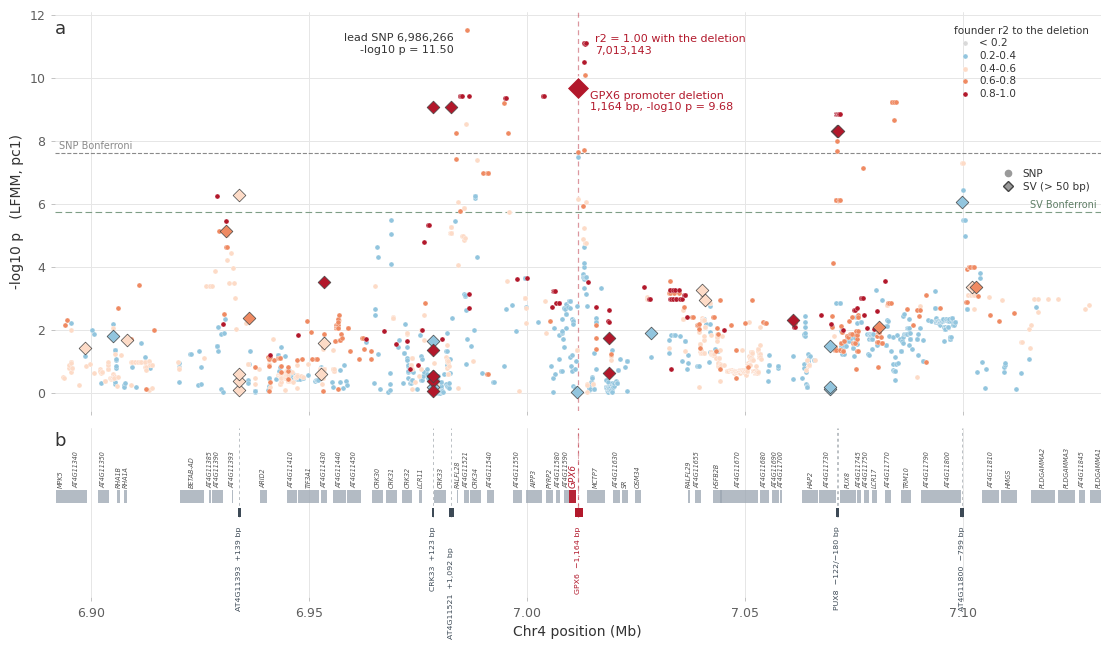

significant SVs marked in panel b:
      sym target_gene placement     pos  ref_len  alt_len  dlen    MAF  carriers    nlp     r2
     GPX6   AT4G11600  promoter 7011705     1225       61 -1164 0.1177        13 9.6844 1.0000
    CRK33   AT4G11490  promoter 6978538        1      124   123 0.1011        12 9.0842 0.9091
AT4G11521   AT4G11521  promoter 6982683      909     2001  1092 0.1011        12 9.0842 0.9091
     PUX8   AT4G11740  promoter 7071146      123        1  -122 0.0996        11 8.2936 0.8209
     PUX8   AT4G11740  promoter 7071304      181        1  -180 0.0996        11 8.2936 0.8209
AT4G11393   AT4G11393   nearest 6934090        1      140   139 0.1781        18 6.2675 0.5400
AT4G11800   AT4G11800  promoter 7099846      800        1  -799 0.2514        56 6.0408 0.2344


In [5]:

draw_zoom(f"gpx6_ld_zoom_{AXIS_LD}_candidates", mark_candidates=True)
print("significant SVs marked in panel b:")
print(SVSIG.sort_values("nlp", ascending=False)[["sym", "target_gene", "placement", "pos",
      "ref_len", "alt_len", "dlen", "MAF", "carriers", "nlp", "r2"]].round(4).to_string(index=False))
